# Mapas interactivos con Folium

[Folium](https://python-visualization.github.io/folium/) es una librería que permite crear mapas interactivos desde Python. Por debajo usa [Leaflet](https://leafletjs.com/), una librería JavaScript de mapas: Folium genera el código HTML y JavaScript del mapa, que podemos ver en el propio notebook o guardar como fichero HTML para abrirlo en el navegador.

Para instalarla: `pip install folium`. En este notebook usaremos también `vega_datasets` (`pip install vega_datasets`), que trae algunos datasets de ejemplo.

**Ficheros de datos** (carpeta `data/`):
* `indiana_outline_map.geojson`: contorno del estado de Indiana
* `sales_region1.geojson`, `sales_region2.geojson`, `sales_region3.geojson`: regiones de venta ficticias
* `geojson_indiana_counties.geojson`: condados de Indiana
* `indiana_population_by_county.csv`: población por condado de Indiana
* `flags_of_africa.png`: banderas de África (de Wikipedia)
* `provincias-espanolas 2.0.geojson`: provincias de España
* `decesos_espania.csv`: defunciones por comunidad autónoma

**Documentación:** https://python-visualization.github.io/folium/

## Imports

In [1]:
import json

import folium  # pip install folium
from folium import plugins
import numpy as np
import pandas as pd
from vega_datasets import data as vds  # pip install vega_datasets

## Mapas básicos

Un mapa vacío se crea con `folium.Map()`. Por defecto muestra el mundo entero:

In [2]:
folium.Map()

Lo normal es indicarle la ubicación (`location`, como `[latitud, longitud]`) y el nivel de zoom inicial (`zoom_start`). Con `control_scale=True` añadimos una escala y con `tiles` elegimos el mapa base (más abajo vemos las opciones). Por ejemplo, el centro de Madrid:

In [3]:
map1 = folium.Map(location=[40.421607657699575, -3.692644648319164],
                  tiles='Esri.WorldStreetMap',
                  zoom_start=16,
                  # width=700,
                  # height=500,
                  control_scale=True)
map1

## Guardar el mapa

Los mapas se guardan como un fichero HTML que se abre en cualquier navegador (con conexión a internet, porque las librerías y las teselas se descargan al abrirlo).

**Ojo con OpenStreetMap:** sus servidores los mantienen voluntarios y su [política de uso](https://operations.osmfoundation.org/policies/tiles/) bloquea las peticiones que no indican desde qué web se hacen. Al abrir el HTML como fichero local (doble clic) el navegador no envía esa información, y el mapa puede mostrar el aviso *403 Access blocked*. Por eso, para los mapas que vamos a guardar usamos las teselas de Esri (`tiles='Esri.WorldStreetMap'`). Dentro del notebook OpenStreetMap funciona sin problema.

In [4]:
map1.save('map1.html')

## Tipos de mapa (capas de teselas)

El aspecto del mapa base lo dan las *teselas* (*tiles*). Podemos añadir varias capas y un control (`LayerControl`, arriba a la derecha) para cambiar entre ellas. Las que usamos aquí son gratuitas; otras, como las de *Stamen* o *CARTO* (`CartoDB positron`, `CartoDB dark_matter`, que verás en muchos ejemplos de internet), ahora necesitan una clave de API: sin ella, el mapa muestra el aviso *API KEY REQUIRED*.

In [5]:
# Mapa
map_layer_control = folium.Map(location=[40.416719, -3.684016], zoom_start=12)

# Añadimos capas de teselas al mapa (el mapa ya trae OpenStreetMap por defecto).
# Con show=False la capa está disponible en el control pero no se muestra al principio
folium.TileLayer('OpenTopoMap', show=False).add_to(map_layer_control)
folium.TileLayer('Esri.WorldImagery', name='Satélite (Esri)', show=False).add_to(map_layer_control)
folium.TileLayer('Esri.WorldGrayCanvas', name='Gris claro (Esri)', show=False).add_to(map_layer_control)

# Control de capas para elegir el mapa
folium.LayerControl().add_to(map_layer_control)

map_layer_control

Los *plugins* añaden funcionalidades. Por ejemplo, un minimapa de referencia y un botón de pantalla completa:

In [6]:
map_with_mini = folium.Map(location=[40.416719, -3.684016], tiles='Esri.WorldStreetMap', zoom_start=7)

minimap = plugins.MiniMap(tile_layer='Esri.WorldStreetMap', toggle_display=True)
map_with_mini.add_child(minimap)

plugins.Fullscreen(position='topright').add_to(map_with_mini)

map_with_mini.save('map_with_mini.html')
map_with_mini

## Marcadores

[Documentación de `folium.Marker`](https://python-visualization.github.io/folium/latest/reference.html#folium.map.Marker)

Vamos a situar en el mapa algunos aeropuertos de Estados Unidos, usando el dataset `airports` de `vega_datasets`:

In [7]:
airports = vds.airports()
airports = airports[:25]
airports.head()

,iata,name,city,state,country,latitude,longitude
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944


Recorremos el DataFrame y añadimos un marcador por fila. `popup` es el texto que aparece al hacer clic y `tooltip` el que aparece al pasar el ratón:

In [8]:
# Mapa
map_airports = folium.Map(location=[38, -98], zoom_start=4)

# Un marcador por aeropuerto
for index, row in airports.iterrows():
    folium.Marker(location=[row['latitude'], row['longitude']],
                  popup=row['name'] + ' ' + row['city'],
                  tooltip='click').add_to(map_airports)

map_airports

Lo mismo, pero con `apply` en lugar de un bucle:

In [9]:
map_airports2 = folium.Map(location=[38, -98], zoom_start=4)

airports.apply(lambda row: folium.Marker(location=[row['latitude'], row['longitude']],
                                         popup=row['name'] + ' ' + row['city']).add_to(map_airports2),
               axis=1)

map_airports2

También podemos partir de un diccionario con el nombre de cada lugar y sus coordenadas:

In [10]:
markers_dict = {'Los Angeles': [34.041008, -118.246653],
                'Las Vegas': [36.169726, -115.143996],
                'Denver': [39.739448, -104.992450],
                'Chicago': [41.878765, -87.643267],
                'Manhattan': [40.782949, -73.969559]}

# Cada elemento es una tupla (nombre, [latitud, longitud])
for elemento in markers_dict.items():
    print(elemento)

('Los Angeles', [34.041008, -118.246653])
('Las Vegas', [36.169726, -115.143996])
('Denver', [39.739448, -104.99245])
('Chicago', [41.878765, -87.643267])
('Manhattan', [40.782949, -73.969559])


In [11]:
map_cities = folium.Map(location=[41, -99], zoom_start=4)

for nombre, coordenadas in markers_dict.items():
    folium.Marker(location=coordenadas, popup=nombre).add_to(map_cities)

map_cities

## Marcadores personalizados

[Documentación de `folium.Icon`](https://python-visualization.github.io/folium/latest/reference.html#folium.map.Icon)

Con `folium.Icon` cambiamos el color y el icono del marcador. Los iconos pueden ser de [Font Awesome](https://fontawesome.com/v4/icons/) (`prefix='fa'`) o de [Bootstrap Glyphicons](https://getbootstrap.com/docs/3.3/components/#glyphicons) (`prefix='glyphicon'`):

In [12]:
map_cm_fa = folium.Map(location=[38, -98], zoom_start=4)

# Icono de Font Awesome
folium.Marker(location=[38, -98],
              popup='popup',
              icon=folium.Icon(color='green', icon='bolt', prefix='fa')).add_to(map_cm_fa)

map_cm_fa

In [13]:
map_cm_glyphicon = folium.Map(location=[38, -98], zoom_start=4)

# Icono de Glyphicons
folium.Marker(location=[38, -98],
              popup='popup',
              icon=folium.Icon(icon='glyphicon-plane', prefix='glyphicon')).add_to(map_cm_glyphicon)

map_cm_glyphicon

Varios marcadores, cada uno con su icono, a partir de un DataFrame:

In [14]:
cm_df = pd.DataFrame({'city': ['Los Angeles', 'Las Vegas', 'Denver', 'Chicago', 'Manhattan'],
                      'latitude': [34.041008, 36.169726, 39.739448, 41.878765, 40.782949],
                      'longitude': [-118.246653, -115.143996, -104.992450, -87.643267, -73.969559],
                      'icon': ['bicycle', 'car', 'bus', 'truck', 'motorcycle']})
cm_df

,city,latitude,longitude,icon
0,Los Angeles,34.041008,-118.246653,bicycle
1,Las Vegas,36.169726,-115.143996,car
2,Denver,39.739448,-104.992450,bus
3,Chicago,41.878765,-87.643267,truck
4,Manhattan,40.782949,-73.969559,motorcycle


In [15]:
map_cm_multiple = folium.Map(location=[38, -98], zoom_start=4)

# itertuples recorre las filas como tuplas con nombre (más rápido que iterrows)
for i in cm_df.itertuples():
    folium.Marker(location=[i.latitude, i.longitude],
                  popup=i.city,
                  icon=folium.Icon(icon=i.icon, prefix='fa')).add_to(map_cm_multiple)

map_cm_multiple

Marcadores numerados con el plugin `BeautifyIcon`:

In [16]:
cm_enum_df = pd.DataFrame({'city': ['Los Angeles', 'Las Vegas', 'Denver', 'Chicago', 'Manhattan'],
                           'latitude': [34.041008, 36.169726, 39.739448, 41.878765, 40.782949],
                           'longitude': [-118.246653, -115.143996, -104.992450, -87.643267, -73.969559],
                           'icon_num': [1, 2, 3, 4, 5]})

map_enum_icons = folium.Map([38, -98], zoom_start=4)

for i in cm_enum_df.itertuples():
    folium.Marker(location=[i.latitude, i.longitude],
                  popup=i.city,
                  icon=plugins.BeautifyIcon(number=i.icon_num,
                                            border_color='blue',
                                            border_width=1,
                                            text_color='red',
                                            inner_icon_style='margin-top:0px;')).add_to(map_enum_icons)

map_enum_icons

## Círculos

* `folium.Circle`: el radio se indica en **metros**, así que su tamaño en pantalla cambia con el zoom.
* `folium.CircleMarker`: el radio se indica en **píxeles**, así que su tamaño en pantalla es fijo.

In [17]:
map_circle = folium.Map(location=[38, -98], zoom_start=4)

# Radio en metros
folium.Circle(radius=100000, location=[38, -98], color='green').add_to(map_circle)

# Radio en píxeles
folium.CircleMarker(location=[39, -105], radius=25, color='blue', fill_color='yellow').add_to(map_circle)

map_circle

## Rutas

Con `PolyLine` unimos una lista de coordenadas:

In [18]:
map_plot_route = folium.Map(location=[38, -98], zoom_start=4)

# Lista de [latitud, longitud] (también vale una lista de tuplas)
route_lats_longs = [[34.041008, -118.246653],
                    [36.169726, -115.143996],
                    [39.739448, -104.992450],
                    [41.878765, -87.643267],
                    [40.782949, -73.969559]]

folium.PolyLine(route_lats_longs).add_to(map_plot_route)

map_plot_route

El plugin `AntPath` dibuja la ruta animada, indicando el sentido del recorrido:

In [19]:
map_ant_route = folium.Map(location=[38, -98], zoom_start=4)

plugins.AntPath(route_lats_longs).add_to(map_ant_route)

map_ant_route

## Capas GeoJSON

[GeoJSON](https://geojson.org/) es un formato estándar para representar geometrías (puntos, líneas, polígonos) junto con sus propiedades. Podemos cargar un fichero o una URL.

* Para crear tus propios GeoJSON puedes usar [geojson.io](https://geojson.io) o el plugin `Draw` que veremos más abajo.
* Los *shapefiles* se pueden convertir a GeoJSON con QGIS o con la librería `geopandas`.

In [20]:
map_geojson = folium.Map(location=[39.77, -86.15], zoom_start=7)

folium.GeoJson('data/indiana_outline_map.geojson', name='geojson indiana').add_to(map_geojson)

# Control de capas para activar o desactivar la capa
folium.LayerControl().add_to(map_geojson)

map_geojson

### Subgrupos de capas

Con `FeatureGroup` y el plugin `FeatureGroupSubGroup` agrupamos capas, de forma que se puedan activar o desactivar todas a la vez o una a una:

In [21]:
map_with_subgroups = folium.Map(location=[39.77, -86.15], zoom_start=7)

# Grupo con todas las regiones
all_subgroups = folium.FeatureGroup(name='todas las regiones de venta')
map_with_subgroups.add_child(all_subgroups)

# Subgrupos
sales_region1 = plugins.FeatureGroupSubGroup(all_subgroups, 'región de venta 1')
map_with_subgroups.add_child(sales_region1)

sales_region2 = plugins.FeatureGroupSubGroup(all_subgroups, 'región de venta 2')
map_with_subgroups.add_child(sales_region2)

sales_region3 = plugins.FeatureGroupSubGroup(all_subgroups, 'región de venta 3')
map_with_subgroups.add_child(sales_region3)

# Cargamos los GeoJSON en cada subgrupo
folium.GeoJson('data/sales_region1.geojson').add_to(sales_region1)
folium.GeoJson('data/sales_region2.geojson').add_to(sales_region2)
folium.GeoJson('data/sales_region3.geojson').add_to(sales_region3)

folium.LayerControl(collapsed=False).add_to(map_with_subgroups)

map_with_subgroups

## Mapas de coropletas

[Documentación de `folium.Choropleth`](https://python-visualization.github.io/folium/latest/reference.html#folium.features.Choropleth)

Un mapa de coropletas colorea cada región según el valor de una variable. Necesitamos dos cosas:
* un **GeoJSON** con las geometrías de las regiones (en este caso, los condados de Indiana);
* unos **datos** con el valor de cada región (la población de cada condado).

Y una clave común para unirlos. Veamos primero cómo es el GeoJSON:

In [22]:
with open('data/geojson_indiana_counties.geojson') as f:
    geo_json_counties = json.load(f)

# Cada condado es una "feature" con su geometría y sus propiedades
geo_json_counties['features'][0]['properties']

{'AREA': 835203110.44822,
 'PERIMETER': 116410.31836,
 'NAME_U': 'STEUBEN',
 'NAME_L': 'Steuben',
 'NCAPC': 76,
 'CNTY_FIPS': '151',
 'STFID': '18151',
 'POP2000': 33214,
 'WHITE': 32281,
 'BLACK': 123,
 'AMERI_ES': 109,
 'ASIAN': 133,
 'HAWN_PI': 6,
 'OTHER': 283,
 'MULT_RACE': 279,
 'HISPANIC': 683,
 'MALES': 16771,
 'FEMALES': 16443,
 'AGE_UNDER5': 2199,
 'AGE_5_17': 6322,
 'AGE_18_21': 2241,
 'AGE_22_29': 3307,
 'AGE_30_39': 4832,
 'AGE_40_49': 4966,
 'AGE_50_64': 5411,
 'AGE_65_UP': 3936,
 'MED_AGE': 35.5,
 'MED_AGE_M': 34.2,
 'MED_AGE_F': 36.9,
 'HOUSEHOLDS': 12738,
 'AVE_HH_SZ': 2.53,
 'HSEHLD_1_M': 1462,
 'HSEHLD_1_F': 1634,
 'MARHH_CHD': 3057,
 'MARHH_NO_C': 4208,
 'MHH_CHILD': 375,
 'FHH_CHILD': 715,
 'FAMILIES': 8911,
 'AVE_FAM_SZ': 3.0,
 'HSE_UNITS': 17337,
 'VACANT': 4599,
 'OWNER_OCC': 9951,
 'RENTER_OCC': 2787}

Usaremos como clave el nombre del condado (`NAME_L`). Lo copiamos al campo `id` de cada *feature*:

In [23]:
for feature in geo_json_counties['features']:
    feature['id'] = feature['properties']['NAME_L']

In [24]:
pop_df = pd.read_csv('data/indiana_population_by_county.csv')
pop_df.head()

,County,State,Population
0,Adams,Indiana,35636
1,Allen,Indiana,375351
2,Bartholomew,Indiana,82753
3,Benton,Indiana,8653
4,Blackford,Indiana,11930


Con `columns` indicamos la columna de los datos que contiene la clave y la que contiene el valor, y con `key_on` dónde está la clave dentro del GeoJSON:

In [25]:
map_choropleth = folium.Map(location=[39.77, -86.15], zoom_start=7)

folium.Choropleth(
    geo_data=geo_json_counties,
    name='choropleth',
    data=pop_df,
    columns=['County', 'Population'],
    key_on='feature.id',
    fill_color='YlGn',
    fill_opacity=0.5,
    line_opacity=0.5,
    legend_name='Población',
    highlight=True
).add_to(map_choropleth)

# Control de capas para activar o desactivar la coropleta
folium.LayerControl().add_to(map_choropleth)

map_choropleth

### Coropletas de España

Defunciones por todas las causas en cada comunidad autónoma. Ahora la clave es el nombre de la comunidad, que en el GeoJSON de provincias está en la propiedad `ccaa` de cada provincia:

In [26]:
decesos_df = pd.read_csv('data/decesos_espania.csv', sep=';', index_col=0)

# Quitamos la fila del total nacional, que no es una comunidad
decesos_df = decesos_df[decesos_df['Comunidad Autónoma'] != 'NACIONAL']
decesos_df.head()

,Comunidad Autónoma,Todas las causas
0,Andalucía,0.812273
1,Aragón,1.026278
2,"Asturias, Principado de",1.224578
3,Illes Balears,0.709636
4,Canarias,0.676349


In [27]:
m = folium.Map(location=[40, -3.7], zoom_start=5)

# Capa de teselas adicional para poder elegir el tipo de vista
folium.TileLayer('OpenTopoMap', show=False).add_to(m)

folium.Choropleth(
    geo_data='data/provincias-espanolas 2.0.geojson',
    name='choropleth',
    data=decesos_df,
    columns=['Comunidad Autónoma', 'Todas las causas'],
    key_on='feature.properties.ccaa',  # dónde está la clave dentro del GeoJSON
    fill_color='BuPu',
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name='Defunciones (todas las causas) por comunidad autónoma'
).add_to(m)

folium.LayerControl().add_to(m)

m

## Mapas de calor

[Documentación de `HeatMapWithTime`](https://python-visualization.github.io/folium/latest/user_guide/plugins/heatmap_with_time.html)

El plugin `HeatMapWithTime` muestra un mapa de calor que evoluciona en el tiempo. Necesita una lista con un elemento por instante; cada elemento es a su vez una lista de puntos `[latitud, longitud]`. Lo probamos con datos aleatorios:

In [28]:
# 100 instantes con 20 puntos aleatorios cada uno, alrededor de (39, -98)
heatmap_time_data = (np.random.random((100, 20, 2)) + np.array([[39, -98]])).tolist()

# Una fecha por instante
heatmap_time_dates = [d.strftime('%Y-%m-%d') for d in pd.date_range('20160101', periods=len(heatmap_time_data))]

map_heatmap_time = folium.Map([39, -98], zoom_start=6)

heatmap_time_plugin = plugins.HeatMapWithTime(heatmap_time_data, index=heatmap_time_dates)
heatmap_time_plugin.add_to(map_heatmap_time)

map_heatmap_time

## Herramientas

### Latitud y longitud

Con `LatLngPopup`, al hacer clic en el mapa aparecen las coordenadas de ese punto:

In [29]:
map_lat_long = folium.Map(location=[38, -98], zoom_start=4)

map_lat_long.add_child(folium.LatLngPopup())

map_lat_long

### Medir distancias y áreas

[Documentación de `MeasureControl`](https://python-visualization.github.io/folium/latest/user_guide/plugins/measure_control.html)

In [30]:
map_measure = folium.Map([40, -100], zoom_start=4)

measure_control = plugins.MeasureControl(position='topleft',
                                         active_color='red',
                                         completed_color='red',
                                         primary_length_unit='meters')
map_measure.add_child(measure_control)

map_measure

### Mapa doble

`DualMap` muestra dos mapas sincronizados uno al lado del otro. Con el control de capas de cada uno podemos, por ejemplo, comparar el callejero con la vista de satélite:

In [31]:
map_dual = plugins.DualMap(location=[40, -98], tiles=None, zoom_start=4)

folium.TileLayer('OpenStreetMap').add_to(map_dual)
folium.TileLayer('Esri.WorldImagery', name='Satélite (Esri)').add_to(map_dual)

folium.LayerControl().add_to(map_dual)

map_dual

### Dibujar

[Documentación de `Draw`](https://python-visualization.github.io/folium/latest/user_guide/plugins/draw.html)

El plugin `Draw` permite dibujar formas sobre el mapa. Con `export=True` aparece un botón para exportar lo dibujado como fichero GeoJSON:

In [32]:
map_draw = folium.Map(location=[40, -99], zoom_start=4)

draw = plugins.Draw(export=True)
draw.add_to(map_draw)

map_draw

## Superponer una imagen

Con `ImageOverlay` colocamos una imagen sobre el mapa indicando las coordenadas de sus esquinas (`bounds`). Por ejemplo, un mapa de banderas de África de Wikipedia:


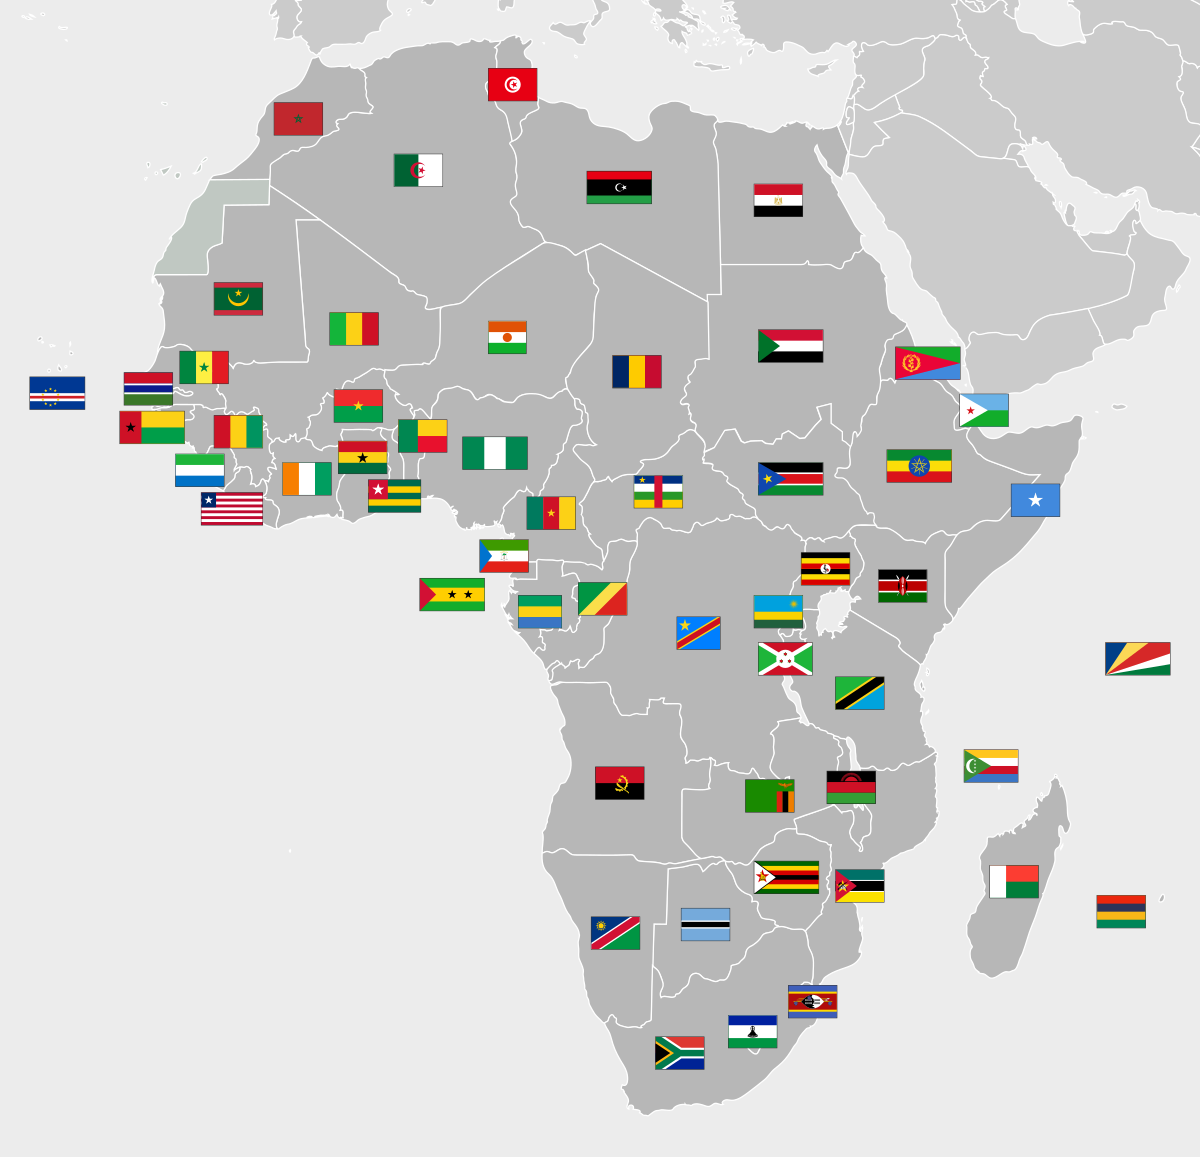

In [33]:
map_img_overlay = folium.Map([2, 22], zoom_start=3)

img_overlay = folium.raster_layers.ImageOverlay(name='banderas de África',
                                                image='data/flags_of_africa.png',
                                                # bounds: [[lat_min, lon_min], [lat_max, lon_max]]
                                                bounds=[[-38, -28], [40, 60]],
                                                opacity=0.5)
img_overlay.add_to(map_img_overlay)

folium.LayerControl().add_to(map_img_overlay)

map_img_overlay